# 실습 2. 위성영상 분류: 직접 학습 vs 전이학습 vs CLIP
**통계청 AI 교육 · 2026.10.27(화)**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sunghoonim/stat-ai-2026/blob/main/lab2_satellite_cnn_vs_clip.ipynb)

### 오늘의 목표
- 같은 위성영상에 **네 가지 방법**을 써 보고 정확도를 비교한다
  1. 작은 CNN을 **처음부터** 학습
  2. ImageNet으로 **사전학습된 CNN**의 특징 + 로지스틱 회귀 (전이학습)
  3. 글과 그림을 함께 배운 **CLIP**으로 라벨 없이 분류 (zero-shot)
  4. CLIP의 특징 + 로지스틱 회귀
- **라벨이 몇 장 있어야** 쓸 만한지 표본 크기별로 확인한다
- **모델을 바꿔 가며** (학습 데이터·언어·크기가 다른 CLIP) 정확도와 속도를 비교한다
- 글로 위성사진을 **검색**해 본다

| 단계 | 내용 | 시간 |
|---|---|---|
| 1단계 | 데이터 보기 | 5분 |
| 2단계 | 작은 CNN 처음부터 학습 | 10분 |
| 3단계 | 전이학습: 사전학습 CNN + 로지스틱 회귀 | 5분 |
| 4단계 | CLIP: 라벨 없이 분류, 프롬프트 바꾸기 | 15분 |
| 5단계 | 라벨 몇 장이면 될까? | 5분 |
| 6단계 | 모델 바꿔 보기 | 10분 |
| 7단계 | 글로 위성사진 찾기 | 5분 |
| 8단계 | (선택) 영상에 잡음·흔들림이 있으면? | 5분 |

### 사용법
1. 메뉴 **런타임 → 런타임 유형 변경 → CPU**로 충분합니다. GPU(T4)를 쓸 수 있으면 4·6단계가 몇 배 빨라집니다.
2. 메뉴 **런타임 → 모두 실행**. 처음에는 모델을 내려받느라 몇 분 걸립니다(CLIP 1개 약 600MB).
3. 이 노트북에는 **실행 결과가 미리 저장되어 있습니다.** 실행이 막혀도 결과를 보며 따라오세요. 다시 실행하면 숫자가 조금 다를 수 있습니다(난수·버전 차이).
4. 그림 속 글자는 영어입니다. Colab 기본 글꼴에 한글이 없어서 그렇습니다.

### 코드 속 4요소 표시 (실습 1과 같음)
| 표시 | 요소 | 통계로 말하면 |
|---|---|---|
| 🟦 **Data** | 데이터 | 표본 $(X, y)$ |
| 🟩 **Model** | 모델 | 회귀식 (가중치 = 계수) |
| 🟧 **Loss** | 손실함수 | 음의 로그우도 |
| 🟥 **Optimizer** | 최적화 | 계수를 찾는 수치최적화 방법 |

## 0. 준비

In [1]:
import warnings; warnings.filterwarnings("ignore")
import io, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import sklearn, transformers
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"   # GPU가 있으면 GPU, 없으면 CPU
transformers.logging.set_verbosity_error()                 # 모델을 불러올 때 나오는 긴 안내문 숨기기
t_start = time.time()

print("PyTorch", torch.__version__, "| transformers", transformers.__version__,
      "| scikit-learn", sklearn.__version__, "| device:", device)

PyTorch 2.14.1 | transformers 5.20.1 | scikit-learn 1.9.1 | device: cpu


In [2]:
#@title 🎨 그림·기록 도우미 함수 (실행만 하세요. 내용은 몰라도 됩니다)
plt.rcParams.update({"figure.dpi": 90})
CLASSES = ["AnnualCrop", "Forest", "HerbaceousVeg", "Highway", "Industrial",
           "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]

def show_images(imgs, titles=None, ncols=10, size=1.3, suptitle=""):
    """사진 여러 장을 격자로 그린다."""
    nrows = (len(imgs) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows + (0.4 if suptitle else 0)), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i, im in enumerate(imgs):
        ax = axes.ravel()[i]
        ax.imshow(im)
        if titles is not None:
            ax.set_title(titles[i], fontsize=7)
    if suptitle:
        fig.suptitle(suptitle, fontsize=11)
    fig.tight_layout(); plt.show()

def plot_confusion(y_true, y_pred, title=""):
    """혼동행렬: 행 = 정답, 열 = 예측"""
    cm = confusion_matrix(y_true, y_pred, labels=range(10))
    fig, ax = plt.subplots(figsize=(5.4, 4.8))
    ax.imshow(cm, cmap="Blues")
    for i in range(10):
        for j in range(10):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES, fontsize=7)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=10)
    fig.tight_layout(); plt.show()

scores = {}
def record(name, acc, n_labels, seconds):
    """방법별 결과를 모아 둔다 (마지막에 표로 비교)."""
    scores[name] = {"평가 정확도": acc, "사용한 라벨 수": n_labels, "걸린 시간(초)": seconds}
    print(f"{name}: 정확도 {acc:.1%} | 라벨 {n_labels:,}장 | {seconds:.0f}초")

---
## 1단계. 🟦 데이터 보기 (5분)
**EuroSAT**: 유럽연합 위성 **Sentinel-2**가 찍은 유럽 34개국 위성영상입니다. 한 장은 64×64 화소이고 화소 하나가 10m라서, 사진 한 장이 **약 640m × 640m** 땅입니다.
토지피복 10종류로 라벨이 붙어 있습니다. 원래 27,000장 중 공개된 평가용 2,700장(약 9MB)을 내려받아, 분류마다 **학습용 100장 + 평가용 50장**만 씁니다.

| 번호 | 그림 속 이름 | 토지피복 |
|---|---|---|
| 0 | AnnualCrop | 일년생 작물 경작지 (밭) |
| 1 | Forest | 산림 |
| 2 | HerbaceousVeg | 초지 · 관목지 |
| 3 | Highway | 도로 |
| 4 | Industrial | 산업 · 상업 시설 |
| 5 | Pasture | 목초지 |
| 6 | PermanentCrop | 영년생 작물 (과수원 · 포도밭) |
| 7 | Residential | 주거지 |
| 8 | River | 하천 |
| 9 | SeaLake | 바다 · 호수 |

In [3]:
#@title 위성영상 내려받기 (약 9MB)
DATA_URL = "https://huggingface.co/datasets/tanganke/eurosat/resolve/main/data/{}-00000-of-00001.parquet"

def load_eurosat(split="test"):
    df = pd.read_parquet(DATA_URL.format(split))
    images = [Image.open(io.BytesIO(b["bytes"])).convert("RGB") for b in df["image"]]
    return images, df["label"].to_numpy()

all_images, all_labels = load_eurosat("test")
print(f"{len(all_images):,}장 | 한 장 크기 {all_images[0].size[0]}×{all_images[0].size[1]} 화소")

2,700장 | 한 장 크기 64×64 화소


학습용 1,000장 | 평가용 500장 | 분류 10개 → 아무렇게나 찍으면 정확도 10%


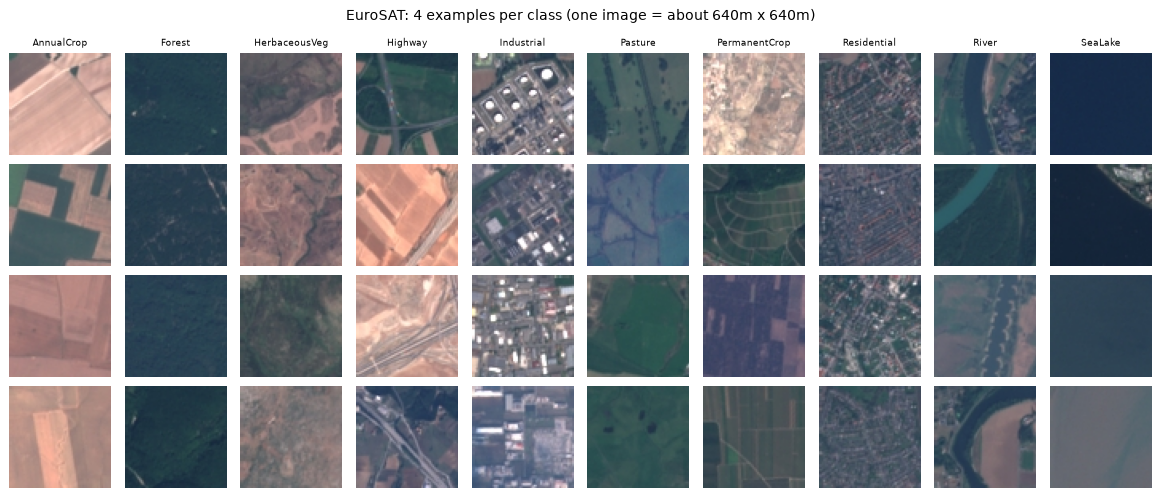

In [4]:
# 분류마다 학습용 100장, 평가용 50장을 무작위로 뽑습니다 (층화추출)
rng = np.random.RandomState(SEED)
tr_idx, te_idx = [], []
for c in range(10):
    idx = rng.permutation(np.where(all_labels == c)[0])
    tr_idx += list(idx[:100]); te_idx += list(idx[100:150])
train_imgs, y_tr = [all_images[i] for i in tr_idx], all_labels[tr_idx]
test_imgs,  y_te = [all_images[i] for i in te_idx], all_labels[te_idx]
print(f"학습용 {len(train_imgs):,}장 | 평가용 {len(test_imgs)}장 | 분류 10개 → 아무렇게나 찍으면 정확도 10%")

show_images([train_imgs[c * 100 + i] for i in range(4) for c in range(10)],
            [CLASSES[c] if i == 0 else "" for i in range(4) for c in range(10)],
            suptitle="EuroSAT: 4 examples per class (one image = about 640m x 640m)")

> ✅ **확인할 것**: 사람 눈에도 헷갈리는 쌍이 보이나요?
> 밭(AnnualCrop) · 목초지(Pasture) · 과수원(PermanentCrop), 하천(River) · 도로(Highway), 초지(HerbaceousVeg) · 산림(Forest).
> 이 쌍은 뒤에서 모델도 자주 헷갈립니다.

---
## 2단계. 처음부터 학습하기: 작은 CNN (10분)
2-(1) 강의에서 본 **CNN**을 직접 만듭니다. 3×3 필터가 사진을 훑으며 모서리·질감 같은 특징을 찾고(Conv), 사진 크기를 절반씩 줄입니다(MaxPool). 이것을 세 번 반복한 뒤 10개 분류의 점수를 냅니다.

- 🟩 **Model:** [Conv → ReLU → MaxPool] × 3 + 완전연결층 2개. 가중치 약 29만 개를 **무작위 값에서 시작**합니다.
- 🟧 **Loss:** `CrossEntropyLoss` = **다항 로지스틱 회귀의 음의 로그우도**. 실습 1의 이진 교차엔트로피를 분류 10개로 넓힌 것입니다.
- 🟥 **Optimizer:** Adam, 학습률 0.001, 32장씩 미니배치

학습용 사진 1,000장만으로 배웁니다.

In [5]:
# 🟦 Data: 사진 → 숫자 묶음 (장 수, 색 3채널, 64, 64). 채널별로 표준화
def to_tensor(imgs):
    return torch.tensor(np.stack([np.asarray(im) for im in imgs]), dtype=torch.float32).permute(0, 3, 1, 2) / 255

X_tr_t, X_te_t = to_tensor(train_imgs), to_tensor(test_imgs)
mu, sd = X_tr_t.mean((0, 2, 3), keepdim=True), X_tr_t.std((0, 2, 3), keepdim=True)
X_tr_t, X_te_t = (X_tr_t - mu) / sd, (X_te_t - mu) / sd
Y_tr_t, Y_te_t = torch.tensor(y_tr), torch.tensor(y_te)
print("학습용 데이터 모양:", tuple(X_tr_t.shape))

def small_cnn():
    # 🟩 Model: [Conv → ReLU → MaxPool] × 3 → 완전연결층
    return nn.Sequential(
        nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 64×64 → 32×32
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # → 16×16
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # → 8×8
        nn.Flatten(), nn.Linear(64 * 8 * 8, 64), nn.ReLU(), nn.Linear(64, 10))

def augment(xb):
    """위성사진은 위아래·방향이 의미 없으므로, 뒤집고 돌려도 같은 땅입니다."""
    if torch.rand(1) < 0.5: xb = xb.flip(3)
    if torch.rand(1) < 0.5: xb = xb.flip(2)
    return torch.rot90(xb, int(torch.randint(4, (1,))), (2, 3))

def train_cnn(epochs=25, use_augment=False, seed=SEED):
    torch.manual_seed(seed)
    model = small_cnn().to(device)                                   # 🟩 Model
    loss_fn = nn.CrossEntropyLoss()                                  # 🟧 Loss
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)        # 🟥 Optimizer
    acc = lambda X, Y: (model(X.to(device)).argmax(1).cpu() == Y).float().mean().item()
    hist = {"train": [], "test": []}
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(Y_tr_t))
        for i in range(0, len(perm), 32):                            # 🟦 32장씩 미니배치
            b = perm[i:i + 32]
            xb = augment(X_tr_t[b]) if use_augment else X_tr_t[b]
            optimizer.zero_grad()
            loss = loss_fn(model(xb.to(device)), Y_tr_t[b].to(device))
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            hist["train"].append(acc(X_tr_t, Y_tr_t)); hist["test"].append(acc(X_te_t, Y_te_t))
        if (epoch + 1) % 5 == 0:
            print(f"epoch {epoch + 1:2d} | 학습용 정확도 {hist['train'][-1]:.1%} | 평가용 정확도 {hist['test'][-1]:.1%}")
    return model, hist

print(f"가중치 수: {sum(p.numel() for p in small_cnn().parameters()):,}개\n")
t = time.time()
cnn, cnn_hist = train_cnn()
record("① CNN 처음부터", cnn_hist["test"][-1], 1000, time.time() - t)

학습용 데이터 모양: (1000, 3, 64, 64)
가중치 수: 286,442개



epoch  5 | 학습용 정확도 69.8% | 평가용 정확도 61.2%


epoch 10 | 학습용 정확도 81.8% | 평가용 정확도 64.4%


epoch 15 | 학습용 정확도 89.0% | 평가용 정확도 69.0%


epoch 20 | 학습용 정확도 92.8% | 평가용 정확도 63.2%


epoch 25 | 학습용 정확도 98.1% | 평가용 정확도 68.4%
① CNN 처음부터: 정확도 68.4% | 라벨 1,000장 | 33초


### 2-1. 데이터 늘리기(증강): 뒤집고 돌려서 보여 주기
같은 모델을 이번에는 미니배치마다 사진을 무작위로 **뒤집고 90°씩 돌려서** 보여 줍니다.

epoch  5 | 학습용 정확도 59.1% | 평가용 정확도 56.6%


epoch 10 | 학습용 정확도 68.7% | 평가용 정확도 65.8%


epoch 15 | 학습용 정확도 73.4% | 평가용 정확도 66.2%


epoch 20 | 학습용 정확도 77.5% | 평가용 정확도 69.0%


epoch 25 | 학습용 정확도 82.1% | 평가용 정확도 72.4%
① CNN 처음부터 + 증강: 정확도 72.4% | 라벨 1,000장 | 33초


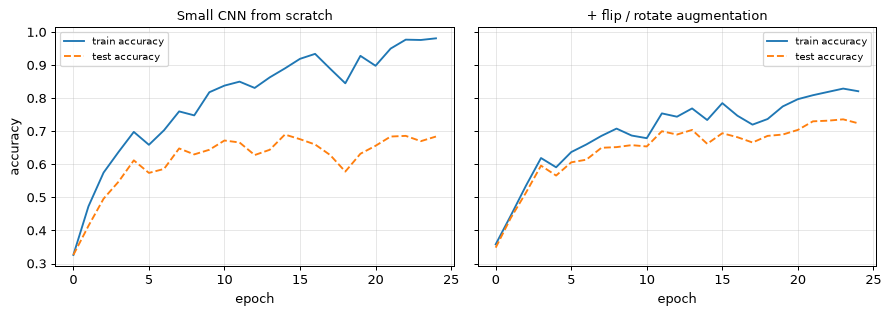

In [6]:
t = time.time()
cnn_aug, cnn_aug_hist = train_cnn(use_augment=True)
record("① CNN 처음부터 + 증강", cnn_aug_hist["test"][-1], 1000, time.time() - t)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, h, title in [(axes[0], cnn_hist, "Small CNN from scratch"),
                     (axes[1], cnn_aug_hist, "+ flip / rotate augmentation")]:
    ax.plot(h["train"], label="train accuracy"); ax.plot(h["test"], "--", label="test accuracy")
    ax.set_xlabel("epoch"); ax.set_title(title, fontsize=10); ax.legend(fontsize=8); ax.grid(alpha=0.3)
axes[0].set_ylabel("accuracy"); fig.tight_layout(); plt.show()

> ✅ **확인할 것**
> - 왼쪽: 학습용 정확도는 100%에 가까워지는데 평가용은 60%대에서 멈춥니다. 실습 1에서 본 **과적합**입니다. 가중치 29만 개를 사진 1,000장으로 추정하니 표본이 모자랍니다.
> - 오른쪽: 뒤집고 돌린 사진을 보여 주면 학습용 정확도는 천천히 오르지만 **평가용 정확도는 더 높아집니다.** '위성사진은 방향이 의미 없다'는 **사전 지식**을 데이터에 넣은 것입니다.
> - 그래도 70%대입니다. 원본 27,000장 전체와 사전학습 모델을 쓰면 98% 안팎까지 보고되어 있습니다. **사진이 적을 때는 어떻게 할까요?** → 3단계

---
## 3단계. 전이학습: 사전학습 CNN + 로지스틱 회귀 (5분)
**ImageNet**(사진 약 120만 장, 1,000종류: 개, 자동차, 꽃 …)으로 이미 학습된 **ResNet18**을 가져옵니다. 위성사진은 한 장도 본 적 없는 모델입니다.
마지막 분류층을 떼어 내고, 그 직전에 나오는 **숫자 512개를 사진의 특징**으로 씁니다. 그 위에 **로지스틱 회귀**를 얹습니다.

실습 1의 4단계(문장 → 사전학습 모델 → 숫자 768개 → 로지스틱 회귀)와 **똑같은 구조**입니다. 문장이 사진으로 바뀌었을 뿐입니다.

In [7]:
#@title ResNet18 불러오기 (약 45MB)
import torchvision
weights = torchvision.models.ResNet18_Weights.DEFAULT
resnet = torchvision.models.resnet18(weights=weights).eval().to(device)
resnet.fc = nn.Identity()            # 마지막 분류층(1,000종류)을 떼어 내고 특징 512개만 꺼냄
preprocess = weights.transforms()    # 224×224로 키우고 ImageNet 기준으로 표준화

@torch.no_grad()
def resnet_features(imgs, batch_size=64):
    out = []
    for i in range(0, len(imgs), batch_size):
        x = torch.stack([preprocess(im) for im in imgs[i:i + batch_size]]).to(device)
        out.append(resnet(x).cpu())
    return torch.cat(out).numpy()

In [8]:
def linear_probe(F_train, y_train, F_test, y_test, C=0.1):
    """특징 → 표준화 → 다항 로지스틱 회귀 (L2 벌점, C = 1/λ). 평가 정확도와 모델을 돌려준다."""
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000)).fit(F_train, y_train)
    return clf.score(F_test, y_test), clf

t = time.time()
R_tr, R_te = resnet_features(train_imgs), resnet_features(test_imgs)     # 🟦 사진 → 특징 512개
print("특징 모양:", R_tr.shape, "→ 사진 1,000장 × 숫자 512개")
acc, _ = linear_probe(R_tr, y_tr, R_te, y_te)                            # 🟩 다항 로지스틱 회귀
record("② ResNet18 특징 + 로지스틱 회귀", acc, 1000, time.time() - t)

특징 모양: (1000, 512) → 사진 1,000장 × 숫자 512개
② ResNet18 특징 + 로지스틱 회귀: 정확도 88.8% | 라벨 1,000장 | 30초


> ✅ **확인할 것**: 같은 1,000장인데 ①보다 **16~20%p** 오릅니다. 학습도 몇 초면 끝납니다.
> 큰 데이터로 미리 배운 **'사진을 보는 눈'**(가장자리, 질감, 색 패턴)을 빌려 쓴 덕분입니다. 통계로 말하면, 다른 큰 표본에서 얻은 정보로 좋은 **설명변수**를 만들어 쓴 것입니다.

---
## 4단계. CLIP: 글과 그림을 함께 배운 모델 (15분)
### 4-1. CLIP은 '짝 맞히기'로 배웁니다
**CLIP**(OpenAI, 2021)은 인터넷에서 모은 **사진-설명 4억 쌍**으로 "이 사진과 이 글이 짝인가?"를 맞히도록 학습했습니다.
- 사진 인코더: 사진 → 숫자 512개
- 글 인코더: 문장 → 숫자 512개
- 짝이 맞는 사진과 글은 두 벡터의 방향이 비슷해지도록(코사인 유사도 ↑) 학습

그래서 **분류 이름을 글로 써 주기만 하면** 라벨 없이도 분류할 수 있습니다. 사진마다 가장 가까운 글을 고르면 됩니다. 이것을 **zero-shot 분류**라고 합니다.

In [9]:
#@title CLIP 불러오기 (처음 한 번 약 600MB 다운로드)
from transformers import AutoModel, AutoProcessor

def load_clip(name):
    model = AutoModel.from_pretrained(name).eval().to(device)
    processor = AutoProcessor.from_pretrained(name)
    return model, processor

def _as_tensor(out):
    return out if torch.is_tensor(out) else out.pooler_output   # transformers 버전에 따라 반환 형식이 다름

@torch.no_grad()
def encode_images(clip, imgs, batch_size=64):
    """사진 목록 → 사진마다 숫자 벡터 (길이 1로 정규화 → 내적 = 코사인 유사도)"""
    model, processor = clip
    feats = []
    for i in range(0, len(imgs), batch_size):
        px = processor(images=imgs[i:i + batch_size], return_tensors="pt").to(device)
        feats.append(_as_tensor(model.get_image_features(**px)).cpu())
    return F.normalize(torch.cat(feats), dim=-1).numpy()

@torch.no_grad()
def encode_texts(clip, texts):
    """글 목록 → 글마다 숫자 벡터 (사진과 같은 공간)"""
    model, processor = clip
    pad = dict(padding="max_length", max_length=64) if "siglip" in model.config.model_type else dict(padding=True)
    tx = processor(text=list(texts), return_tensors="pt", **pad).to(device)
    return F.normalize(_as_tensor(model.get_text_features(**tx)).cpu(), dim=-1).numpy()

clip_b32 = load_clip("openai/clip-vit-base-patch32")
t = time.time()
C_tr, C_te = encode_images(clip_b32, train_imgs), encode_images(clip_b32, test_imgs)
clip_seconds = time.time() - t
print(f"사진 {len(train_imgs) + len(test_imgs):,}장 → 숫자 {C_tr.shape[1]}개씩 | {clip_seconds:.0f}초")

사진 1,500장 → 숫자 512개씩 | 16초


### 4-2. 짝 맞히기 표: 사진 5장 × 설명 5개
강의 슬라이드의 'CLIP 짝 맞히기 표'를 직접 만들어 봅니다. 칸의 숫자는 사진과 설명의 코사인 유사도입니다.

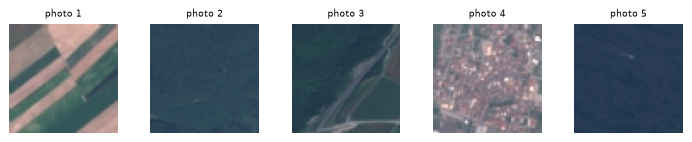

,사진 1,사진 2,사진 3,사진 4,사진 5
a satellite photo of farmland,0.315,0.298,0.325,0.289,0.244
a satellite photo of a forest,0.292,0.287,0.304,0.270,0.240
a satellite photo of a highway,0.295,0.293,0.323,0.285,0.253
a satellite photo of houses,0.318,0.294,0.314,0.347,0.262
a satellite photo of the sea,0.275,0.286,0.269,0.260,0.288


In [10]:
pick = [0, 1, 3, 7, 9]    # AnnualCrop, Forest, Highway, Residential, SeaLake
demo_imgs = [test_imgs[c * 50 + 1] for c in pick]
demo_texts = ["a satellite photo of farmland", "a satellite photo of a forest", "a satellite photo of a highway",
              "a satellite photo of houses", "a satellite photo of the sea"]
show_images(demo_imgs, [f"photo {j + 1}" for j in range(5)], ncols=5, size=1.6)

S = encode_images(clip_b32, demo_imgs) @ encode_texts(clip_b32, demo_texts).T
pd.DataFrame(S.T, index=demo_texts, columns=[f"사진 {j + 1}" for j in range(5)]) \
  .style.background_gradient(cmap="Blues", axis=0).format("{:.3f}")

> ✅ **확인할 것**: 열(사진)마다 가장 진한 칸이 맞는 설명인가요?
> - 밭·주택·바다 사진은 맞는 설명이 가장 높습니다. 그런데 몇 장은 엉뚱한 설명이 더 높게 나옵니다(저장된 결과에서는 숲·도로 사진이 'farmland' 쪽).
> - 유사도 값은 0.2~0.3으로 작고, 칸 사이 차이는 0.01 안팎입니다. 중요한 것은 값의 크기가 아니라 **순서**입니다.
> - 차이가 이렇게 작다는 것은 CLIP에게 **위에서 내려다본 작은 위성사진이 어려운 사진**이라는 신호입니다. 평가용 500장 전체로 재 봅니다.

### 4-3. 라벨 없이 분류하기 (zero-shot)
분류 10개의 이름을 글로 바꾸고, 사진마다 가장 가까운 이름을 고릅니다. 학습용 사진도, 라벨도 쓰지 않습니다.

In [11]:
NAMES = ["annual crop land", "forest", "brushland or shrubland", "highway or road",
         "industrial buildings or commercial buildings", "pasture land", "permanent crop land",
         "residential buildings or homes or apartments", "river", "lake or sea"]

def zero_shot(clip, F_img, texts):
    """사진마다 가장 비슷한 글을 고른다."""
    return (F_img @ encode_texts(clip, texts).T).argmax(1)

pred = zero_shot(clip_b32, C_te, NAMES)
print(f"zero-shot 정확도: {(pred == y_te).mean():.1%}   (아무렇게나 찍으면 10%)")

zero-shot 정확도: 43.8%   (아무렇게나 찍으면 10%)


### 4-4. 프롬프트(글)를 바꾸면?
같은 모델, 같은 사진인데 **분류 이름을 어떻게 쓰느냐**만 바꿉니다.

In [12]:
TEMPLATES = ["a satellite photo of {}.", "a centered satellite photo of {}.",
             "an aerial photo of {}.", "a satellite image of {}."]

def zero_shot_ensemble(clip, F_img, names, templates):
    """문장 틀 여러 개로 만든 글 벡터를 평균 내서 분류 (프롬프트 앙상블)"""
    T = np.mean([encode_texts(clip, [t.format(n) for n in names]) for t in templates], axis=0)
    T /= np.linalg.norm(T, axis=1, keepdims=True)
    return (F_img @ T.T).argmax(1)

t = time.time()
prompt_preds = {
    "① 폴더 이름 그대로 (AnnualCrop, SeaLake …)": zero_shot(clip_b32, C_te, [
        "AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial",
        "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]),
    "② 풀어 쓴 이름 (annual crop land …)": zero_shot(clip_b32, C_te, NAMES),
    "③ 문장으로 (a satellite photo of …)": zero_shot(clip_b32, C_te, [TEMPLATES[0].format(n) for n in NAMES]),
    "④ 문장 틀 4개 평균 (프롬프트 앙상블)": zero_shot_ensemble(clip_b32, C_te, NAMES, TEMPLATES),
}
zs_pred = prompt_preds["④ 문장 틀 4개 평균 (프롬프트 앙상블)"]
record("③ CLIP zero-shot (라벨 0장)", (zs_pred == y_te).mean(), 0, clip_seconds / 3 + time.time() - t)
pd.DataFrame({"zero-shot 정확도": {k: (v == y_te).mean() for k, v in prompt_preds.items()}}).style.format("{:.1%}")

③ CLIP zero-shot (라벨 0장): 정확도 46.4% | 라벨 0장 | 6초


,zero-shot 정확도
"① 폴더 이름 그대로 (AnnualCrop, SeaLake …)",34.8%
② 풀어 쓴 이름 (annual crop land …),43.8%
③ 문장으로 (a satellite photo of …),42.2%
④ 문장 틀 4개 평균 (프롬프트 앙상블),46.4%


> ✅ **확인할 것**
> - 이름만 바꿨는데 정확도가 10%p 넘게 달라집니다. `SeaLake`처럼 붙여 쓴 폴더 이름은 사람이 쓰는 말이 아니라서 불리합니다. 생성형 AI에서 말하는 **"프롬프트를 잘 쓰라"**와 같은 이야기입니다.
> - 문장 틀 하나(③)가 항상 낫지는 않습니다. 여러 개를 **평균**(④)하면 안정적입니다. 통계에서 여러 추정치를 평균해 분산을 줄이는 것과 같습니다.
> - 그래도 50% 안팎으로, 라벨을 써서 학습한 ②(약 89%)보다 한참 낮습니다. 어디서 틀릴까요?

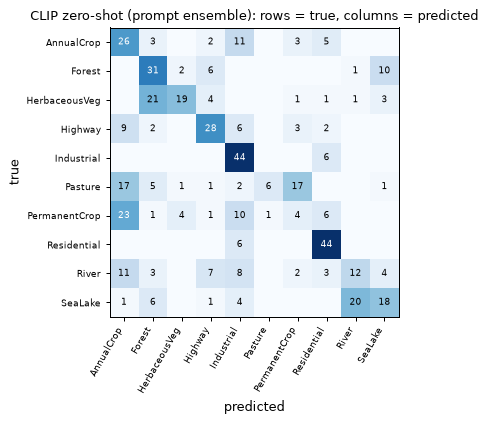

In [13]:
plot_confusion(y_te, zs_pred, "CLIP zero-shot (prompt ensemble): rows = true, columns = predicted")

> ✅ **확인할 것**: 대각선 밖의 큰 숫자가 헷갈린 곳입니다.
> - 건물이 보이는 **산업·주거지**는 50장 중 40장 넘게 맞힙니다.
> - **목초지·과수원**은 거의 못 맞히고 밭(AnnualCrop)으로 몰아 줍니다. 초지는 산림으로, 바다·호수는 하천으로 많이 착각합니다. 1단계에서 사람 눈에도 헷갈렸던 쌍입니다.
> - CLIP은 인터넷 사진(사람이 땅에서 찍은 일상 사진)과 설명으로 배웠습니다. **위에서 내려다본 64×64 화소 사진**에서 'pasture land'와 'annual crop land'를 가르는 법은 거의 배운 적이 없습니다.

### 4-5. 한국어로 물어보면?

In [14]:
NAMES_KO = ["경작지", "산림", "초지", "도로", "산업 단지", "목초지", "과수원", "주거 지역", "하천", "바다나 호수"]
TEMPLATES_KO = ["{}의 위성 사진"]

pred_ko = zero_shot_ensemble(clip_b32, C_te, NAMES_KO, TEMPLATES_KO)
print(f"한국어 이름으로 zero-shot: {(pred_ko == y_te).mean():.1%}   (아무렇게나 찍으면 10%)\n")
tok = clip_b32[1].tokenizer
print("영어 'forest'  →", tok.tokenize("forest"))
print("한국어 '산림'  →", tok.tokenize("산림"))

한국어 이름으로 zero-shot: 12.0%   (아무렇게나 찍으면 10%)

영어 'forest'  → ['forest</w>']
한국어 '산림'  → ['ìĤ', '°', 'ë¦', '¼</w>']


> ✅ 거의 찍는 수준입니다. 이 CLIP은 **영어 설명으로만** 배웠습니다. 위 출력처럼 한국어 '산림'은 뜻 있는 단위가 아니라 알아볼 수 없는 바이트 조각으로 쪼개집니다.
> 한국어로 쓰려면 **한국어를 배운 모델**이 필요합니다. → 6단계에서 바꿔 봅니다.

### 4-6. 라벨을 쓰면: CLIP 특징 + 로지스틱 회귀
3단계와 똑같이 하되, 특징만 ResNet18 대신 **CLIP 사진 인코더**의 512개 숫자로 바꿉니다.

In [15]:
t = time.time()
acc, clip_probe = linear_probe(C_tr, y_tr, C_te, y_te)
record("④ CLIP 특징 + 로지스틱 회귀", acc, 1000, clip_seconds + time.time() - t)

④ CLIP 특징 + 로지스틱 회귀: 정확도 91.6% | 라벨 1,000장 | 16초


---
## 5단계. 라벨 몇 장이면 될까? (5분)
실제 업무에서는 라벨(정답)을 사람이 붙여야 해서 비쌉니다. 분류마다 라벨을 **1, 2, 4, … , 100장**만 주고 ②(ResNet18 특징)와 ④(CLIP 특징)를 비교합니다.
같은 장수라도 어떤 사진이 뽑히느냐에 따라 결과가 달라지므로, **5번 반복해서 평균과 표준편차**를 냅니다. (100장은 전부 쓰므로 1번)

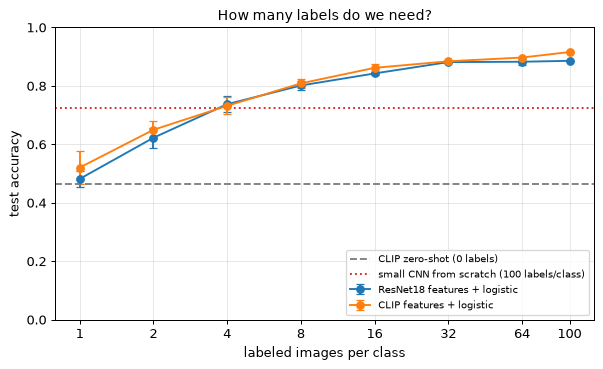

k,1장,2장,4장,8장,16장,32장,64장,100장
ResNet18 특징 + 로지스틱,48.2%,62.3%,73.8%,80.2%,84.3%,88.2%,88.3%,88.6%
CLIP 특징 + 로지스틱,52.1%,65.0%,73.2%,80.9%,86.2%,88.4%,89.7%,91.6%


In [16]:
K_LIST = [1, 2, 4, 8, 16, 32, 64, 100]

def label_curve(F_train, F_test, repeats=5):
    rows = []
    for k in K_LIST:
        accs = []
        for r in range(repeats if k < 100 else 1):
            rng = np.random.RandomState(r)
            pick = np.concatenate([rng.choice(np.where(y_tr == c)[0], k, replace=False) for c in range(10)])
            accs.append(linear_probe(F_train[pick], y_tr[pick], F_test, y_te)[0])
        rows.append((k, np.mean(accs), np.std(accs)))
    return pd.DataFrame(rows, columns=["k", "mean", "sd"]).set_index("k")

curves = {"ResNet18 features + logistic": label_curve(R_tr, R_te),
          "CLIP features + logistic": label_curve(C_tr, C_te)}

fig, ax = plt.subplots(figsize=(6.8, 4.2))
for name, c in curves.items():
    ax.errorbar(c.index, c["mean"], yerr=c["sd"], marker="o", capsize=3, label=name)
ax.axhline(scores["③ CLIP zero-shot (라벨 0장)"]["평가 정확도"], color="gray", ls="--", label="CLIP zero-shot (0 labels)")
ax.axhline(scores["① CNN 처음부터 + 증강"]["평가 정확도"], color="C3", ls=":", label="small CNN from scratch (100 labels/class)")
ax.set_xscale("log", base=2); ax.set_xticks(K_LIST); ax.set_xticklabels(K_LIST)
ax.set_xlabel("labeled images per class"); ax.set_ylabel("test accuracy"); ax.set_ylim(0, 1)
ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower right")
ax.set_title("How many labels do we need?", fontsize=11)
plt.tight_layout(); plt.show()

pd.DataFrame({n.split(" features")[0] + " 특징 + 로지스틱": c["mean"] for n, c in curves.items()}).T \
  .rename(columns=lambda k: f"{k}장").style.format("{:.1%}")

> ✅ **확인할 것**
> - 분류마다 **1장**만 있어도 CLIP zero-shot(회색 점선)과 비슷하거나 낫습니다. **16장**이면 80%대, 100장이면 90% 안팎입니다.
> - 처음부터 학습한 CNN(빨간 점선)은 분류마다 100장을 쓰고도, 사전학습 특징에 **4~8장**만 준 것과 비슷합니다.
> - 라벨이 아주 적을 때는 막대(표준편차)가 깁니다. **어떤 사진에 라벨을 붙이느냐**에 따라 결과가 크게 흔들립니다. 표본이 작을 때 추정량의 분산이 큰 것과 같습니다.
>
> 💬 **실무 순서**: ① 라벨 없이 zero-shot으로 가능성을 본다 → ② 분류마다 수십 장씩 라벨을 붙여 로지스틱 회귀를 얹는다 → ③ 그래도 부족하면 그때 모델 전체를 미세조정한다.

---
## 6단계. 모델 바꿔 보기 (10분)
CLIP에도 여러 종류가 있습니다. 모델을 바꿀 때마다 같은 사진 1,500장으로 네 가지를 잽니다: **zero-shot 정확도(영어 · 한국어)**, **라벨 100장/분류 정확도**, **속도**.

| 모델 | 무엇이 다른가 |
|---|---|
| `openai/clip-vit-base-patch32` | 4단계에서 쓴 기본 CLIP (OpenAI, 비공개 사진-설명 4억 쌍) |
| `laion/CLIP-ViT-B-32-laion2B-s34B-b79K` | **구조와 크기는 똑같고 학습 데이터만 다름** (공개 데이터 LAION-2B, 약 20억 쌍) |
| `Bingsu/clip-vit-base-patch32-ko` | 사진 인코더는 OpenAI CLIP 그대로 두고, **글 인코더만 한국어**로 다시 학습 |
| (선택) `openai/clip-vit-base-patch16` | 사진을 더 잘게(16×16 화소 조각) 나눠 봄. 더 정밀하지만 약 4배 느림 |
| (선택) `google/siglip2-base-patch16-224` | Google의 2025년 모델. 여러 언어로 학습 |

In [17]:
def evaluate_clip(name, clip=None, feats=None):
    """모델 하나를 같은 기준으로 잰다. 이미 계산한 특징(feats)이 있으면 재사용."""
    clip = clip or load_clip(name)
    t = time.time()
    Ftr, Fte = feats if feats is not None else (encode_images(clip, train_imgs), encode_images(clip, test_imgs))
    sec = clip_seconds if feats is not None else time.time() - t
    row = {
        "가중치 수(백만)": sum(p.numel() for p in clip[0].parameters()) / 1e6,
        "zero-shot (영어)": (zero_shot_ensemble(clip, Fte, NAMES, TEMPLATES) == y_te).mean(),
        "zero-shot (한국어)": (zero_shot_ensemble(clip, Fte, NAMES_KO, TEMPLATES_KO) == y_te).mean(),
        "라벨 100장/분류": linear_probe(Ftr, y_tr, Fte, y_te)[0],
        "초당 사진 수": (len(train_imgs) + len(test_imgs)) / sec,
    }
    print(f"{name}: zero-shot 영어 {row['zero-shot (영어)']:.1%} / 한국어 {row['zero-shot (한국어)']:.1%}"
          f" | 라벨 100장 {row['라벨 100장/분류']:.1%} | 초당 {row['초당 사진 수']:.0f}장")
    return row, clip, (Ftr, Fte)

compare, clips, feats = {}, {}, {}
for name in ["openai/clip-vit-base-patch32", "laion/CLIP-ViT-B-32-laion2B-s34B-b79K", "Bingsu/clip-vit-base-patch32-ko"]:
    reuse = name == "openai/clip-vit-base-patch32"
    compare[name], clips[name], feats[name] = evaluate_clip(
        name, clip=clip_b32 if reuse else None, feats=(C_tr, C_te) if reuse else None)

def show_compare():
    return pd.DataFrame(compare).T.style.format({
        "가중치 수(백만)": "{:.0f}", "zero-shot (영어)": "{:.1%}", "zero-shot (한국어)": "{:.1%}",
        "라벨 100장/분류": "{:.1%}", "초당 사진 수": "{:.0f}"}).background_gradient(
        cmap="Greens", subset=["zero-shot (영어)", "zero-shot (한국어)", "라벨 100장/분류"])
show_compare()

openai/clip-vit-base-patch32: zero-shot 영어 46.4% / 한국어 12.0% | 라벨 100장 91.6% | 초당 93장


laion/CLIP-ViT-B-32-laion2B-s34B-b79K: zero-shot 영어 50.4% / 한국어 9.8% | 라벨 100장 93.0% | 초당 88장


Bingsu/clip-vit-base-patch32-ko: zero-shot 영어 39.6% / 한국어 51.4% | 라벨 100장 91.6% | 초당 91장


,가중치 수(백만),zero-shot (영어),zero-shot (한국어),라벨 100장/분류,초당 사진 수
openai/clip-vit-base-patch32,151,46.4%,12.0%,91.6%,93
laion/CLIP-ViT-B-32-laion2B-s34B-b79K,151,50.4%,9.8%,93.0%,88
Bingsu/clip-vit-base-patch32-ko,151,39.6%,51.4%,91.6%,91


### 6-1. (선택) 더 무거운 모델
CPU에서는 모델마다 **3~5분** 걸립니다. 시간이 없으면 건너뛰고 아래 저장된 결과만 보세요. GPU에서는 1분이 안 걸립니다.
(더 큰 `openai/clip-vit-large-patch14`도 목록에 넣을 수 있지만, CPU에서는 10분 넘게 걸립니다.)

In [18]:
for name in ["openai/clip-vit-base-patch16", "google/siglip2-base-patch16-224"]:
    compare[name], _, _ = evaluate_clip(name)
show_compare()

openai/clip-vit-base-patch16: zero-shot 영어 56.0% / 한국어 4.6% | 라벨 100장 91.2% | 초당 22장


google/siglip2-base-patch16-224: zero-shot 영어 45.0% / 한국어 34.8% | 라벨 100장 92.0% | 초당 19장


,가중치 수(백만),zero-shot (영어),zero-shot (한국어),라벨 100장/분류,초당 사진 수
openai/clip-vit-base-patch32,151,46.4%,12.0%,91.6%,93
laion/CLIP-ViT-B-32-laion2B-s34B-b79K,151,50.4%,9.8%,93.0%,88
Bingsu/clip-vit-base-patch32-ko,151,39.6%,51.4%,91.6%,91
openai/clip-vit-base-patch16,150,56.0%,4.6%,91.2%,22
google/siglip2-base-patch16-224,375,45.0%,34.8%,92.0%,19


> ✅ **확인할 것**
> - **OpenAI vs LAION**: 구조와 크기가 똑같은데 학습 데이터만 다릅니다. 그런데 라벨 100장 정확도와 zero-shot이 모두 달라집니다. **같은 모델 구조라도 무엇으로 학습했느냐**가 성능을 가릅니다.
> - **한국어 CLIP**: 한국어 zero-shot이 찍는 수준에서 크게 오릅니다. 사진 인코더는 OpenAI CLIP과 같아서 **라벨 100장 정확도는 똑같습니다.** 글 쪽만 바꿨다는 증거입니다.
> - **B/16**: 사진을 잘게 나눠 보니 zero-shot은 10%p 가까이 오릅니다. 그런데 **라벨 100장 정확도는 B/32와 거의 같고, 속도는 4분의 1**입니다.
> - **SigLIP2**: 여러 언어로 배워서 영어 CLIP과 달리 한국어도 어느 정도 알아듣습니다. 가중치가 2배 넘게 많고 느리지만, 이 데이터에서 정확도가 크게 높지는 않습니다.
> - **크고 새로운 모델이 항상 이기지는 않습니다.** 라벨을 쓸 수 있다면 작은 모델로 충분한 경우가 많습니다.
>
> 💬 **모델을 고를 때**: 정확도만이 아니라 **처리 속도(=비용), 언어, 라이선스, 우리 데이터와 얼마나 비슷한 데이터로 배웠는지**를 함께 봅니다. 그리고 반드시 **우리 데이터로 직접 재 봅니다.** 지금 이 표처럼요.

---
## 7단계. 글로 위성사진 찾기 (5분)
CLIP은 분류만이 아니라 **검색**에도 씁니다. 검색어를 벡터로 바꾸고, 사진 1,500장 중 가장 가까운 사진을 고릅니다. 라벨은 쓰지 않습니다.
6단계의 **한국어 CLIP**으로 한국어 검색어를 넣어 봅니다. (사진 위 글자는 그 사진의 실제 분류입니다.)

검색어: 공장이 모여 있는 위성 사진


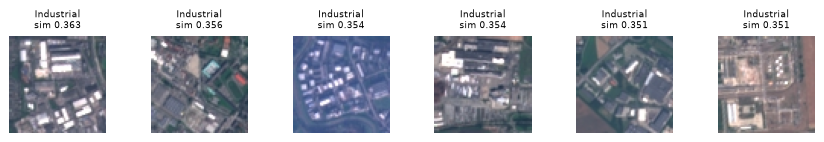

검색어: 고속도로가 지나가는 위성 사진


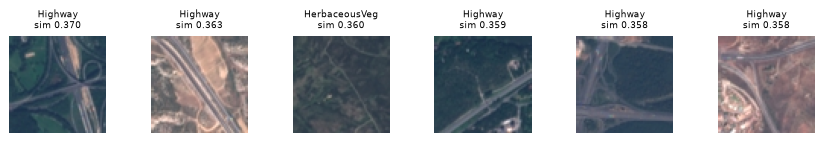

검색어: 아파트 단지


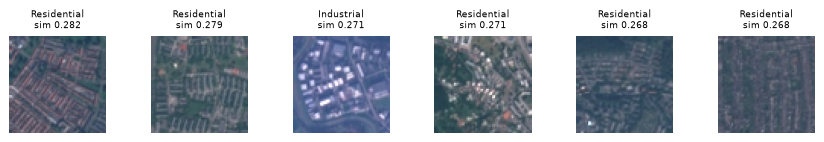

In [19]:
ko_clip = clips["Bingsu/clip-vit-base-patch32-ko"]
F_all = np.concatenate(feats["Bingsu/clip-vit-base-patch32-ko"])
imgs_all, y_all = train_imgs + test_imgs, np.r_[y_tr, y_te]

def search(query, k=6):
    q = encode_texts(ko_clip, [query])[0]
    sim = F_all @ q
    top = np.argsort(-sim)[:k]
    print(f"검색어: {query}")
    show_images([imgs_all[i] for i in top], [f"{CLASSES[y_all[i]]}\nsim {sim[i]:.3f}" for i in top], ncols=k, size=1.6)

for q in ["공장이 모여 있는 위성 사진", "고속도로가 지나가는 위성 사진", "아파트 단지"]:
    search(q)

### 7-1. ✏️ 직접 검색해 보기
검색어를 바꾸고 이 셀만 다시 실행하세요. 예: `울창한 숲`, `바다가 보이는 위성 사진`, `강이 굽이쳐 흐르는 땅`

검색어: 울창한 숲


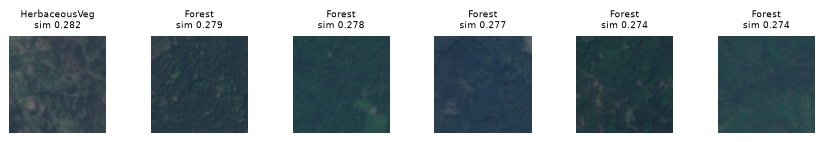

In [20]:
query = "울창한 숲"  #@param {type:"string"}
search(query)

### 🤔 생각해볼 문제
**'논'**을 검색하면 무엇이 나올까요? 먼저 생각해 보고 실행하세요.

검색어: 논


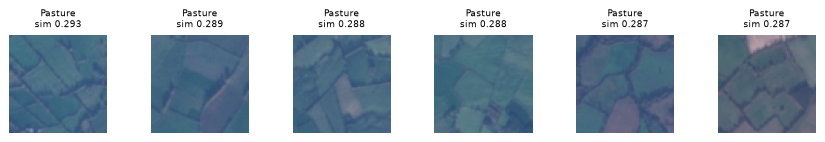

In [21]:
search("논")

<details>
<summary><b>설명 보기</b></summary>

EuroSAT는 **유럽** 사진이라 **논(벼농사)이 없습니다.** 그래도 모델은 "없습니다"라고 하지 않고, 데이터 안에서 **가장 비슷한 것**(주로 목초지나 밭)을 자신 있게 내놓습니다.
- 모델은 항상 무언가를 답합니다. **결과를 사람이 확인해야** 하는 이유입니다.
- 한국 땅(논, 비닐하우스, 계단식 밭, 산지)에 쓰려면 **국내 영상에 라벨을 붙여** 학습 데이터를 만들어야 합니다. 5단계에서 본 것처럼 분류마다 수십 장이면 시작할 수 있습니다.
</details>

---
## 8단계. (선택) 영상에 잡음·흔들림이 있으면? (5분)
같은 평가용 사진 500장에 **잡음**(gaussian noise)과 **흔들림**(motion blur)을 넣은 버전이 공개되어 있습니다.
깨끗한 사진으로 학습한 ④ 모델(CLIP 특징 + 로지스틱 회귀)을 그대로 적용합니다.

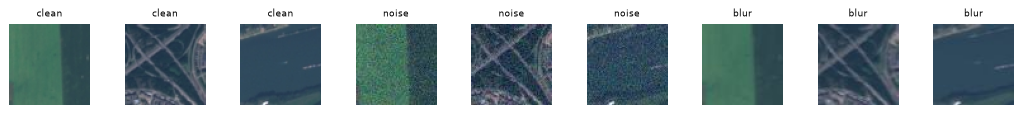

,④ CLIP + 로지스틱 회귀 정확도
깨끗한 사진,91.6%
잡음 (gaussian noise),43.0%
흔들림 (motion blur),53.8%


In [22]:
#@title 잡음·흔들림 버전 내려받아 평가하기 (각 3~5MB)
quality = {"깨끗한 사진": scores["④ CLIP 특징 + 로지스틱 회귀"]["평가 정확도"]}
examples, ex_titles = [test_imgs[c * 50] for c in (0, 3, 8)], ["clean"] * 3
for split, label in [("gaussian_noise", "잡음 (gaussian noise)"), ("motion_blur", "흔들림 (motion blur)")]:
    imgs_c, labels_c = load_eurosat(split)
    test_c = [imgs_c[i] for i in te_idx]
    assert (labels_c[te_idx] == y_te).all()          # 같은 사진, 같은 순서인지 확인
    quality[label] = clip_probe.score(encode_images(clip_b32, test_c), y_te)
    examples += [test_c[c * 50] for c in (0, 3, 8)]; ex_titles += [split.split("_")[-1]] * 3
show_images(examples, ex_titles, ncols=9, size=1.3)
pd.Series(quality, name="④ CLIP + 로지스틱 회귀 정확도").to_frame().style.format("{:.1%}")

> ✅ 학습 때 보지 못한 품질의 영상이 들어오면 정확도가 떨어집니다. 사람 눈에는 여전히 같은 땅인데도요.
> 통계로 말하면 **표본(학습 데이터)이 실제 적용 대상(모집단)을 대표해야** 합니다. 구름, 계절, 촬영 장비가 다른 영상에 쓰려면 그런 영상을 학습 데이터에 넣어야 합니다.

---
## 마무리: 네 가지 방법 비교

In [23]:
pd.DataFrame(scores).T.style.format({"평가 정확도": "{:.1%}", "사용한 라벨 수": "{:,.0f}", "걸린 시간(초)": "{:.0f}"}) \
  .background_gradient(cmap="Greens", subset=["평가 정확도"])

,평가 정확도,사용한 라벨 수,걸린 시간(초)
① CNN 처음부터,68.4%,"1,000",33
① CNN 처음부터 + 증강,72.4%,"1,000",33
② ResNet18 특징 + 로지스틱 회귀,88.8%,"1,000",30
③ CLIP zero-shot (라벨 0장),46.4%,0,6
④ CLIP 특징 + 로지스틱 회귀,91.6%,"1,000",16


| 요소 | ① CNN 처음부터 | ② 전이학습 | ③ CLIP zero-shot | ④ CLIP + 로지스틱 |
|---|---|---|---|---|
| 🟦 **Data** | 사진 1,000장 (+ 뒤집기·회전) | 1,000장 → 특징 512개 | 라벨 0장 + 분류 이름(글) | 1,000장 → 특징 512개 |
| 🟩 **Model** | CNN, 가중치 29만 개를 처음부터 | ResNet18(고정) + 다항 로지스틱 | CLIP 사진·글 인코더(고정) | CLIP 사진 인코더(고정) + 다항 로지스틱 |
| 🟧 **Loss** | 교차엔트로피 | 교차엔트로피 + L2 벌점 | (학습 안 함) | 교차엔트로피 + L2 벌점 |
| 🟥 **Optimizer** | Adam (미니배치) | L-BFGS | - | L-BFGS |

### 오늘의 핵심
1. 데이터가 적으면 처음부터 학습하기보다 **사전학습 모델의 특징을 빌려 쓰는 것**이 훨씬 낫습니다. 실습 1의 문장 분류와 같은 결론입니다.
2. CLIP은 **라벨 없이도** 분류하지만, 위성영상처럼 낯선 분야에서는 **라벨 몇 장**이 훨씬 효과적입니다.
3. 모델을 바꾸면 정확도·속도·언어가 모두 달라집니다. **구조보다 학습 데이터**가 성능을 가를 때가 많습니다.
4. 학습 데이터는 **실제 적용 대상을 대표**해야 합니다(지역, 영상 품질).

### 국가통계와의 연결
- **쓸 수 있는 곳**: 토지피복·토지이용 변화, 농작물 재배면적, 건물·도로 변화 탐지, 재해 피해 면적처럼 **영상으로 면적과 변화를 재는 통계**
- **주의할 점**
  - 오늘 데이터는 유럽 영상입니다. 국내 지형(논, 비닐하우스, 산지)에는 **국내 영상과 라벨**이 필요합니다.
  - 화소 하나가 10m라 건물 하나하나는 구분하기 어렵습니다. **목적에 맞는 해상도**의 영상을 골라야 합니다.
  - 실습 1과 마찬가지로 **확률이 낮은 건은 사람이 검토**하도록 설계합니다.

In [24]:
print(f"전체 실행 시간: {time.time() - t_start:.0f}초")

전체 실행 시간: 349초
